# Assignment 3: Understanding Customer Tipping Behavior

## Q1: Loading and Understanding the Dataset 

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
#Q1.1: Load dataset
tips = sns.load_dataset('tips')

In [4]:
#Q1.2: Display first rows
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [5]:
#Q1.3: Dataset shape and columns
print("Shape:", tips.shape)
print("Columns:", list(tips.columns))

Shape: (244, 7)
Columns: ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']


## Q2: Basic Filtering – Who Tips More?

In [6]:
#Q2.1: Weekend
weekend = tips[tips['day'].isin(['Sat', 'Sun'])]

In [7]:
# weekday
weekdays = tips[~tips['day'].isin(['Sat', 'Sun'])]

In [8]:
#Q2.2: Average tip, Average total bill
print("Weekend  -> tip: %.2f | bill: %.2f" % (weekend['tip'].mean(), weekend['total_bill'].mean()))
print("Weekdays -> tip: %.2f | bill: %.2f" % (weekdays['tip'].mean(), weekdays['total_bill'].mean()))

Weekend  -> tip: 3.12 | bill: 20.89
Weekdays -> tip: 2.76 | bill: 17.56


## Answer Q2.3: Compare this with weekday customers.

### Weekend customers tip about $0.35 more on average ($3.12 vs $2.76). They also spend about $3.33 more per bill ($20.89 vs $17.56), so the higher tips are largely explained by bigger bills. As a share of the bill, the tip is about the same on weekends (16.0%) and weekdays (16.3%).

## Q3: Sorting and Identifying High-Value Customers

In [9]:
# Q3.1: Sort customers by total_bill (descending).
tips_sorted = tips.sort_values('total_bill', ascending=False)

In [10]:
# Q3.2: Display the top 10 highest bills.
tips_sorted.head(10)

,total_bill,tip,sex,smoker,day,time,size
170,50.81,10.00,Male,Yes,Sat,Dinner,3
212,48.33,9.00,Male,No,Sat,Dinner,4
59,48.27,6.73,Male,No,Sat,Dinner,4
156,48.17,5.00,Male,No,Sun,Dinner,6
182,45.35,3.50,Male,Yes,Sun,Dinner,3
102,44.30,2.50,Female,Yes,Sat,Dinner,3
197,43.11,5.00,Female,Yes,Thur,Lunch,4
142,41.19,5.00,Male,No,Thur,Lunch,5
184,40.55,3.00,Male,Yes,Sun,Dinner,2
95,40.17,4.73,Male,Yes,Fri,Dinner,4


### Answer Q3.3: The top 10 bills come from groups of 2 to 6 people, and most have 3 or 4. Only one of the ten is a group of 2, so large bills are mostly driven by larger groups. Nearly all are Saturday or Sunday dinners (one lunch, on a Thursday, and one Friday dinner). Also, the highest bill ($50.81) is not the highest tip-to-bill ratio, since some large bills got small tips (e.g. $3.50 on $45.35).

## Q4: Data Quality Check & Cleaning

In [11]:
#Q4.1: missing values
print(tips.isnull().sum())
print("Total missing:", tips.isnull().sum().sum())

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64
Total missing: 0


### Answer Q4.2: Why missing values are dangerous in machine learning

### Most ML algorithms can't handle missing values and either crash or drop those rows. Dropping rows shrinks the dataset and can introduce bias if the data isn't missing at random. Filling values badly (e.g. with the mean) can distort distributions and relationships between features. Either way, the model learns from incomplete or misleading data, so its predictions become less reliable.

## Q5: Visualization – What Influences Tips? 

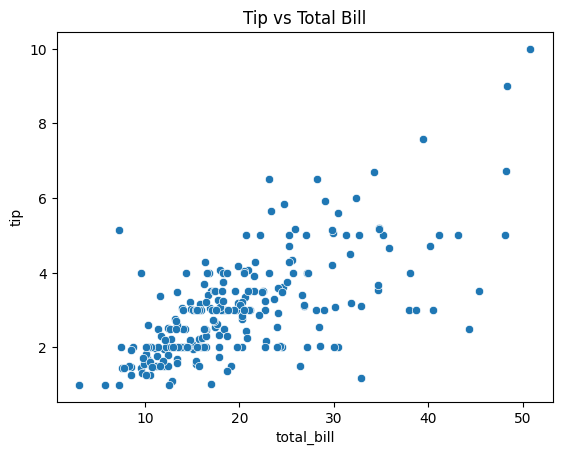

In [12]:
#Q5.1: Tip vs Total Bill (scatter plot)
sns.scatterplot(data=tips, x='total_bill', y='tip')
plt.title('Tip vs Total Bill')
plt.show()

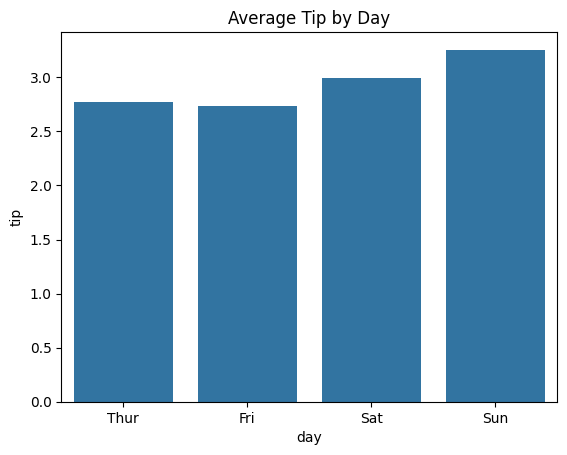

In [17]:
# Q5.1: Average tip by day (bar plot)
sns.barplot(data=tips, x='day', y='tip',errorbar=None)
plt.title('Average Tip by Day')
plt.show()

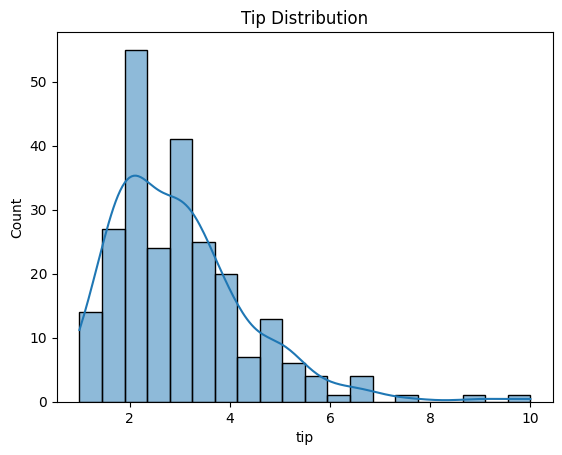

In [20]:
# Q5.1: Tip distribution (histogram)
sns.histplot(data=tips, x='tip', bins=20,kde=True)
plt.title('Tip Distribution')
plt.show()

## Answer Q5.2: Interpret each plot in 1–2 sentences.

### Scatter: There is a clear positive relationship (correlation ≈ 0.68): bigger bills get bigger tips. The spread widens at higher bills, so tips become less predictable.

### Bar plot: Average tips are highest on Sunday ($3.26), then Saturday ($2.99), and lowest on Thursday ($2.77) and Friday ($2.73). The weekend is above the weekdays, but the differences are small.

### Histogram: The distribution is right-skewed, with most tips between $2 and $4 (median $2.90, mean $3.00) and a few large outliers up to $10.

## Q6: Final Insight & Conclusion

### Customers -- Customers with larger bills and larger groups tip the most in dollars, and there is a clear positive relationship between total bill and tip (correlation ≈ 0.68). Weekend customers tip more than weekday customers on average ($3.12 vs $2.76), and tips are highest on Sundays (about $3.26), followed by Saturdays (about $2.99). However, weekend diners also spend more ($20.89 vs $17.56 per bill), and the tip percentage stays around 16% on both weekends and weekdays, so the higher tips come mostly from bigger bills rather than more generous behavior. Smoking status makes almost no difference (about $3.01 vs $2.99), and the small gap between male and female payers ($3.09 vs $2.83) is not strong enough to draw firm conclusions.

### Restaurant managers --  Managers should staff their strongest servers on Saturdays and Sundays, when bills and tips are highest, and encourage group bookings and upselling, since higher bills lead to higher tips. They can also use weekday promotions to attract more customers on slower days, when tips and bills are lower.

In [15]:
tips['tip_pct'] = tips['tip'] / tips['total_bill'] * 100
print(tips.groupby(tips['day'].isin(['Sat','Sun']))['tip_pct'].mean())

day
False    16.330169
True     15.956069
Name: tip_pct, dtype: float64


In [18]:
# Q5.x: Correlation between total_bill and tip
r = tips['total_bill'].corr(tips['tip'])
print("Correlation (Pearson):", round(r, 4))

Correlation (Pearson): 0.6757
